# Model Rekomendasi Tindakan dan Pangan Keluarga 1000 HPK

Notebook ini melatih model yang membantu petugas fasilitas kesehatan (faskes) menjawab dua pertanyaan untuk setiap keluarga dampingan:

1. **Tindakan apa yang perlu dilakukan?** Misalnya rujuk ke dokter/ahli gizi, pantau ulang, konseling, atau PMT.
2. **Makanan apa yang perlu dibeli?** Kelompok pangan yang dipetakan ke kategori produk katalog (Protein, Beras/Pokok, Sayuran, Buah, Susu, Minyak), lengkap dengan porsi anggaran dari kuota mingguan dan contoh keranjang produk.

**Masukan:** skor FIES keluarga, data pertumbuhan anak 0-23 bulan (z-score TB/BB, LiLA, tren dari pengukuran sebelumnya), dan data kehamilan (usia kehamilan, LiLA ibu, hasil pemeriksaan).

## Rancangan singkat

```text
keluarga ──┬─ sasaran 1 (anak / kehamilan) ─► fitur ─► model (1 logistic regression per keputusan)
           ├─ sasaran 2 ...                           │
           └─ skor FIES ──────────────────────────────┘
                                                      ▼
                          kebijakan program + aturan keamanan klinis (selalu berlaku)
                                                      ▼
            AKUMULASI semua sasaran ─► tindakan keluarga, tingkat kebutuhan tiap kelompok pangan
                                                      ▼
                    porsi kuota mingguan per kelompok ─► keranjang produk dari katalog vendor
```

- **Unit prediksi adalah sasaran, bukan keluarga.** Setiap anak atau kehamilan diprediksi sendiri, lalu hasilnya dijumlahkan. Keluarga dengan 1, 2, atau 5 sasaran ditangani dengan cara yang sama.
- **Model hanya mempelajari keputusan yang memang bergantung pada kondisi** (prioritas protein, susu, minyak, rujukan, PMT, dan seterusnya). Keputusan yang merupakan kebijakan tetap (misalnya sayur dan buah selalu dianjurkan, susu tidak untuk bayi di bawah 12 bulan) dan aturan keamanan (z-score < -3 wajib dirujuk) ditegakkan oleh kode, bukan oleh model.
- **Fitur, kebijakan, inferensi, dan akumulasi** ditulis sekali di `apps/backend/app/services/family_recommender.py` (Python standar, tanpa sklearn). Notebook dan backend memakai modul yang sama, sehingga hasil di notebook sama persis dengan hasil di aplikasi.

## Tentang data sintetis

Belum ada data keputusan petugas gizi yang nyata, jadi notebook ini membuat **dunia sintetis** dalam tiga langkah:

1. Keluarga dan sasaran dibangkitkan dengan sebaran yang mendekati keluarga rentan dampingan faskes.
2. Nilai fisik (BB/TB) dihitung balik dari tabel WHO yang sama dengan aplikasi, sehingga z-score dalam data identik dengan hitungan aplikasi.
3. Label dibuat oleh **40 "petugas gizi" simulasi** yang mengikuti pedoman (WHO, Kemenkes: PMBA, Buku KIA, juknis PMT, Isi Piringku), tetapi dengan sedikit perbedaan ambang antarpetugas dan 2% ketidakkonsistenan.

Model belajar dari keputusan yang bervariasi itu, lalu diuji terhadap pedoman tanpa variasi dan terhadap skenario yang ditulis tangan.

> **Batasan:** model hanya sebaik pedoman yang dikodekan. Aturan pangan harus divalidasi ahli gizi (keputusan terbuka #4 di `idea.md`). Setelah faskes memakai fitur ini, simpan keputusan akhir petugas (`FamilyAidPlan`) sebagai data latih nyata. Bagian 5 notebook ini bisa langsung membaca CSV nyata dengan kolom yang sama.

## Cara menjalankan

Jalankan semua sel dari atas ke bawah (sekitar 1-2 menit di laptop). Hasilnya:

| File | Isi |
| --- | --- |
| `ml/family_recommender/data/synthetic_families.csv` | data keluarga sintetis |
| `ml/family_recommender/data/synthetic_members.csv` | data sasaran beserta label keputusan |
| `ml/family_recommender/artifacts/family_recommender_model.json` | model (salinan pelatihan) |
| `ml/family_recommender/artifacts/family_recommender_metrics.json` | laporan evaluasi |
| `app/services/family_recommender_model.json` | salinan model untuk runtime backend |

## 0. Persiapan

Paket yang dibutuhkan hanya untuk pelatihan: `numpy`, `pandas`, `scikit-learn`, `matplotlib`. Backend tidak membutuhkannya.

In [ ]:
# Jalankan sekali bila paket belum ada di kernel ini.
# %pip install numpy==2.1.3 pandas==2.2.3 scikit-learn==1.6.1 matplotlib==3.10.1

In [1]:
from __future__ import annotations

import importlib.util
import json
import sys
from dataclasses import dataclass
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    f1_score,
    fbeta_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)


def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "apps" / "backend" / "app" / "services").exists():
            return candidate
    raise RuntimeError(f"Folder proyek tidak ditemukan dari {start}")


def load_module(name: str, path: Path):
    """Load a single module file without importing the whole backend package (no DB needed)."""
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
BACKEND_DIR = PROJECT_ROOT / "apps" / "backend"
ML_DIR = BACKEND_DIR / "ml" / "family_recommender"
DATA_DIR = ML_DIR / "data"
ARTIFACT_DIR = ML_DIR / "artifacts"
RUNTIME_MODEL_FILE = BACKEND_DIR / "app" / "services" / "family_recommender_model.json"
FAMILIES_CSV = DATA_DIR / "synthetic_families.csv"
MEMBERS_CSV = DATA_DIR / "synthetic_members.csv"
DATA_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Modul yang sama dengan runtime backend.
fr = load_module("family_recommender", BACKEND_DIR / "app" / "services" / "family_recommender.py")
who = load_module("who_growth_standards", BACKEND_DIR / "app" / "utils" / "who_growth_standards.py")

# Konfigurasi eksperimen
SEED = 2026
N_FAMILIES = 8_000
N_RATERS = 40               # jumlah petugas gizi simulasi
LABEL_NOISE = 0.02          # peluang petugas tidak konsisten pada satu keputusan
SPLIT_SHARES = {"train": 0.70, "val": 0.15, "test": 0.15}
REGENERATE_DATA = True      # False = pakai CSV yang ada (misalnya data nyata dengan kolom sama)
MODEL_VERSION = "family-reco-v1-synthetic"

print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | sklearn {sklearn.__version__}")
print(f"Project root : {PROJECT_ROOT}")
print(f"Data         : {DATA_DIR}")
print(f"Artefak      : {ARTIFACT_DIR}")
print(f"Model runtime: {RUNTIME_MODEL_FILE}")

Python 3.12.5 | numpy 2.1.3 | pandas 2.2.3 | sklearn 1.6.1
Project root : D:\T-1\Smstr 7\PPL II\Project\SeribuAsa
Data         : D:\T-1\Smstr 7\PPL II\Project\SeribuAsa\apps\backend\ml\family_recommender\data
Artefak      : D:\T-1\Smstr 7\PPL II\Project\SeribuAsa\apps\backend\ml\family_recommender\artifacts
Model runtime: D:\T-1\Smstr 7\PPL II\Project\SeribuAsa\apps\backend\app\services\family_recommender_model.json


## 1. Basis pengetahuan

Semua ambang dan daftar keputusan berasal dari modul `family_recommender.py`. Tabel di bawah hanya menampilkannya.

**Kelompok pangan.** Model merekomendasikan *kelompok pangan*, bukan produk tertentu, karena produk berbeda per vendor dan wilayah. Setiap kelompok dipetakan ke nama kategori katalog. Bobot biaya mencerminkan perkiraan harga relatif per porsi dan dipakai saat membagi kuota (protein hewani paling mahal per porsi).

**Bayi 0-5 bulan** mendapat ASI eksklusif. Pangan untuk sasaran ini adalah pangan **ibu menyusui**, karena itu susu dan minyak tidak dianjurkan untuk sasaran ini.

In [2]:
food_groups_table = pd.DataFrame(
    [
        {
            "kelompok": g.key,
            "label": g.label,
            "contoh": g.examples,
            "kategori katalog": ", ".join(g.catalog_categories),
            "bobot biaya": g.budget_weight,
        }
        for g in fr.FOOD_GROUPS
    ]
)
actions_table = pd.DataFrame([{"tindakan": a.key, "label": a.label, "keterangan": a.description} for a in fr.ACTIONS])
thresholds_table = pd.DataFrame(
    [
        ("FIES sedang / berat", f">= {fr.FIES_MODERATE_MIN} / >= {fr.FIES_SEVERE_MIN}", "FIESCalculator.classify_score"),
        ("Pendek / BB kurang", f"z-score < {fr.Z_MODERATE}", "WHO Child Growth Standards"),
        ("Sangat pendek / BB sangat kurang", f"z-score < {fr.Z_SEVERE}", "WHO Child Growth Standards"),
        ("LiLA anak gizi kurang / buruk (>= 6 bln)", f"< {fr.CHILD_MUAC_MODERATE_CM} / < {fr.CHILD_MUAC_SEVERE_CM} cm", "WHO"),
        ("Tren menurun", f"perubahan z-score < {fr.DECLINE_DELTA_Z}", "sama dengan ambang tren aplikasi"),
        ("KEK ibu hamil", f"LiLA < {fr.MATERNAL_KEK_MUAC_CM} cm", "Buku KIA (pregnancy.py)"),
        ("Trimester 2 / 3", f"minggu >= {fr.TRIMESTER_2_WEEK} / >= {fr.TRIMESTER_3_WEEK}", ""),
        ("Data perlu diperbarui", f"> {fr.STALE_DATA_DAYS} hari", ""),
    ],
    columns=["indikator", "ambang", "acuan"],
)
heads_table = pd.DataFrame(
    {
        mt: ["dipelajari" if h in fr.LEARNED_HEADS[mt] else "kebijakan" for h in fr.ALL_HEADS]
        for mt in fr.MEMBER_TYPES
    },
    index=fr.ALL_HEADS,
)

display(food_groups_table)
display(actions_table)
display(thresholds_table)
print("Kategori yang tidak pernah direkomendasikan:", fr.NOT_RECOMMENDED_CATEGORIES)
display(heads_table.rename(columns={"child": "anak", "pregnancy": "kehamilan"}))

,kelompok,label,contoh,kategori katalog,bobot biaya
0,protein_hewani,Protein hewani,"telur, ikan, ayam, daging",protein,3.0
1,makanan_pokok,Makanan pokok,beras dan sumber karbohidrat,"beras, pokok",1.5
2,sayuran,Sayuran,sayuran hijau dan berwarna,sayuran,1.0
3,buah,Buah,buah segar,buah,1.0
4,susu,Susu dan olahannya,"susu, yogurt; untuk anak 12 bulan ke atas dan ...",susu,2.0
5,minyak,Minyak/lemak,penambah energi MP-ASI dan makanan tambahan,minyak,0.5


,tindakan,label,keterangan
0,rujuk_nakes,Konsultasikan ke dokter atau ahli gizi,Temuan masuk kategori berat atau memburuk; kon...
1,pantau_ketat,Pantau ulang dalam 2 minggu,Ukur ulang pertumbuhan atau periksa ulang keha...
2,pmt_ibu_hamil,Makanan tambahan (PMT) ibu hamil KEK,Makanan tambahan tinggi energi dan protein unt...
3,pmt_balita,Makanan tambahan (PMT) anak,Untuk anak dengan gizi kurang atau berat badan...
4,konseling_gizi,Berikan konseling gizi,"Konseling ASI eksklusif, MP-ASI, atau gizi ibu..."


,indikator,ambang,acuan
0,FIES sedang / berat,>= 3 / >= 6,FIESCalculator.classify_score
1,Pendek / BB kurang,z-score < -2.0,WHO Child Growth Standards
2,Sangat pendek / BB sangat kurang,z-score < -3.0,WHO Child Growth Standards
3,LiLA anak gizi kurang / buruk (>= 6 bln),< 12.5 / < 11.5 cm,WHO
4,Tren menurun,perubahan z-score < -0.3,sama dengan ambang tren aplikasi
5,KEK ibu hamil,LiLA < 23.5 cm,Buku KIA (pregnancy.py)
6,Trimester 2 / 3,minggu >= 14 / >= 28,
7,Data perlu diperbarui,> 45 hari,


Kategori yang tidak pernah direkomendasikan: {'gula': 'Gula tambahan tidak dianjurkan untuk anak di bawah 2 tahun.', 'bumbu': 'Bumbu bukan sumber zat gizi utama sasaran 1000 HPK.'}


,anak,kehamilan
food_protein_hewani_rec,kebijakan,kebijakan
food_makanan_pokok_rec,kebijakan,kebijakan
food_sayuran_rec,kebijakan,kebijakan
food_buah_rec,kebijakan,kebijakan
food_susu_rec,dipelajari,dipelajari
food_minyak_rec,dipelajari,dipelajari
food_protein_hewani_prio,dipelajari,dipelajari
food_makanan_pokok_prio,dipelajari,dipelajari
food_sayuran_prio,kebijakan,kebijakan
food_buah_prio,kebijakan,kebijakan


## 2. Pembangkit data sintetis

**Populasi:** keluarga rentan yang didampingi faskes. Prevalensinya sengaja sedikit di atas angka nasional (stunting balita SSGI 2022 21,6%, KEK ibu hamil Riskesdas 2018 17,3%) karena sasaran program memang kelompok rentan. Angka ini adalah target kalibrasi demo, bukan statistik resmi.

| Aspek | Asumsi |
| --- | --- |
| Kerentanan | variabel laten per keluarga; memengaruhi FIES, pertumbuhan, dan LiLA (tidak disimpan, tidak dipakai model) |
| FIES | skor 0-8; target sekitar 40% aman, 45% sedang, 15% berat; 5% belum disurvei |
| Komposisi | 1 sasaran (68%), 2 (27%), 3 (5%); maksimal 1 kehamilan per keluarga; 10% anak kedua kembar |
| Anak 0-23 bulan | z-score TB makin rendah seiring usia; z-score BB berkorelasi dengan TB; BB/TB dihitung dari tabel WHO aplikasi lalu z-score dihitung ulang dengan rumus aplikasi |
| Data anak hilang | 7% belum diukur; LiLA hanya untuk >= 6 bulan dan tercatat 55%; 75% punya pengukuran sebelumnya |
| Kehamilan | 6-40 minggu; 12% belum diperiksa; LiLA ibu ~ N(25,4 - 0,8 x kerentanan, 2,0); TFU dan DJJ kadang menyimpang |
| Klasifikasi kehamilan | aturan yang sama dengan `pregnancy.assess_prenatal_check` |

In [3]:
def fies_classification(score) -> str | None:
    if pd.isna(score):
        return None
    return "food_secure" if score <= 2 else "moderate" if score <= 5 else "severe"


def prenatal_classification(weeks: int, lila: float, fundal: float | None, fhr: int | None) -> str:
    """Mirror of app.services.pregnancy.assess_prenatal_check."""
    needs_review = False
    if fundal is not None and 20 <= weeks <= 36 and abs(fundal - weeks) > 2:
        needs_review = True
    if fhr is not None and not 120 <= fhr <= 160:
        needs_review = True
    if needs_review:
        return "needs_review"
    return "kek_risk" if lila < fr.MATERNAL_KEK_MUAC_CM else "normal"


def make_child(rng, vulnerability: float, member_id: str, age: int | None = None) -> dict:
    age = int(rng.integers(0, 24)) if age is None else age
    sex = "male" if rng.random() < 0.51 else "female"
    haz_true = rng.normal(-0.75 - 0.50 * vulnerability - 0.035 * age, 0.95)
    waz_true = 0.55 * haz_true + rng.normal(-0.35 - 0.20 * vulnerability, 0.75)
    row = {"member_id": member_id, "member_type": "child", "age_months": age, "sex": sex}
    if rng.random() >= 0.93:  # belum pernah diukur
        return row

    w_ref = who.get_who_weight_reference(age, sex)
    h_ref = who.get_who_height_reference(age, sex)
    height = round(h_ref["median"] + haz_true * h_ref["sd"] + rng.normal(0, 0.3), 1)
    weight = round(max(1.5, w_ref["median"] + waz_true * w_ref["sd"] + rng.normal(0, 0.05)), 2)
    haz = round((height - h_ref["median"]) / h_ref["sd"], 2)  # rumus ZScoreCalculator
    waz = round((weight - w_ref["median"]) / w_ref["sd"], 2)
    row.update(weight_kg=weight, height_cm=height, haz=haz, waz=waz,
               days_since_measurement=min(int(rng.exponential(20)), 150))

    if age >= fr.CHILD_MUAC_MIN_AGE_MONTHS and rng.random() < 0.55:
        whz_like = waz_true - 0.6 * haz_true
        row["muac_cm"] = round(13.9 + 0.9 * whz_like + rng.normal(0, 0.6), 1)

    if age >= 1 and rng.random() < 0.75:
        delta_haz = rng.normal(-0.04 - 0.06 * vulnerability, 0.28)
        delta_waz = 0.4 * delta_haz + rng.normal(-0.03 - 0.05 * vulnerability, 0.25)
        row.update(prev_haz=round(haz - delta_haz, 2), prev_waz=round(waz - delta_waz, 2),
                   days_between_measurements=int(rng.integers(21, 121)))
    return row


def make_pregnancy(rng, vulnerability: float, member_id: str) -> dict:
    weeks = int(rng.integers(6, 41))
    row = {"member_id": member_id, "member_type": "pregnancy", "gestational_weeks": weeks}
    if rng.random() >= 0.88:  # belum diperiksa
        return row

    lila = round(float(np.clip(rng.normal(25.4 - 0.8 * vulnerability, 2.0), 18.0, 35.0)), 1)
    weight = round(float(np.clip(rng.normal(53 + 0.35 * max(0, weeks - 12) - 1.5 * vulnerability, 7), 35, 110)), 1)
    fundal = None
    if weeks >= 20:
        fundal = weeks + rng.normal(0, 1.0)
        if rng.random() < 0.08:
            fundal += rng.choice([-1, 1]) * rng.uniform(3, 6)
        fundal = round(min(fundal, 42.0) * 2) / 2
    fhr = None
    if weeks >= 12 and rng.random() < 0.85:
        fhr = int(round(rng.normal(142, 7)))
        if rng.random() < 0.04:
            fhr = int(rng.integers(95, 118)) if rng.random() < 0.5 else int(rng.integers(163, 182))
    row.update(
        maternal_weight_kg=weight,
        lila_cm=lila,
        fundal_height_cm=fundal,
        fetal_heart_rate=fhr,
        prenatal_classification=prenatal_classification(weeks, lila, fundal, fhr),
        days_since_check=min(int(rng.exponential(20)), 150),
    )
    return row


def generate_world(seed: int, n_families: int, n_raters: int):
    rng = np.random.default_rng(seed)
    raters = pd.DataFrame({
        "rater_id": np.arange(n_raters),
        "z_shift": rng.normal(0, 0.10, n_raters),
        "muac_shift": rng.normal(0, 0.15, n_raters),
        "lila_shift": rng.normal(0, 0.20, n_raters),
        "decline_shift": rng.normal(0, 0.05, n_raters),
        "fies_shift": rng.choice([-1, 0, 1], size=n_raters, p=[0.1, 0.8, 0.1]),
    })

    vulnerability = rng.normal(0, 1, n_families)
    fies = np.clip(np.rint(3.2 + 2.0 * vulnerability + rng.normal(0, 1.0, n_families)), 0, 8)
    fies_missing = rng.random(n_families) < 0.05
    n_targets = rng.choice([1, 2, 3], size=n_families, p=[0.68, 0.27, 0.05])
    families = pd.DataFrame({
        "family_id": [f"F{i:05d}" for i in range(n_families)],
        "n_targets": n_targets,
        "family_size": n_targets + 1 + rng.poisson(2.0, n_families),
        "fies_score": np.where(fies_missing, np.nan, fies),
        "fies_days_since": np.where(fies_missing, np.nan, np.minimum(rng.exponential(18, n_families).astype(int), 120)),
        "rater_id": rng.integers(0, n_raters, n_families),
    })
    families["fies_classification"] = families["fies_score"].map(fies_classification)

    members = []
    for i, family in enumerate(families.itertuples(index=False)):
        has_pregnancy, previous_child_age = False, None
        for slot in range(family.n_targets):
            member_id = f"{family.family_id}-M{slot + 1}"
            if not has_pregnancy and rng.random() < 0.35:
                row = make_pregnancy(rng, vulnerability[i], member_id)
                has_pregnancy = True
            else:
                twin = previous_child_age is not None and rng.random() < 0.10
                row = make_child(rng, vulnerability[i], member_id, previous_child_age if twin else None)
                previous_child_age = row["age_months"]
            members.append({"family_id": family.family_id, **row})

    member_columns = [
        "member_id", "family_id", "member_type",
        "age_months", "sex", "weight_kg", "height_cm", "haz", "waz", "muac_cm",
        "prev_haz", "prev_waz", "days_between_measurements", "days_since_measurement",
        "gestational_weeks", "maternal_weight_kg", "lila_cm", "fundal_height_cm",
        "fetal_heart_rate", "prenatal_classification", "days_since_check",
    ]
    return families, pd.DataFrame(members).reindex(columns=member_columns), raters

## 3. Label: keputusan petugas gizi simulasi

Setiap keluarga ditangani satu dari 40 petugas simulasi. Pedoman yang diikuti petugas:

**Anak 0-23 bulan.** "Masalah pertumbuhan" berarti pendek, BB kurang, atau LiLA < 12,5 cm. "Kekurangan energi" berarti BB kurang atau LiLA < 12,5 cm. "Tren turun" berarti z-score TB atau BB turun lebih dari 0,3.

| Keputusan | 0-5 bulan (ASI eksklusif) | 6-11 bulan (awal MP-ASI) | 12-23 bulan |
| --- | --- | --- | --- |
| Protein hewani **prioritas** | masalah/tren turun atau FIES berat | selalu | masalah/tren turun atau FIES >= 3 |
| Makanan pokok **prioritas** | FIES berat | FIES berat atau kekurangan energi | FIES berat atau kekurangan energi |
| Susu dianjurkan / prioritas | tidak (kebijakan) | tidak (kebijakan) | selalu / pendek atau BB kurang |
| Minyak dianjurkan | tidak (kebijakan) | selalu (energi MP-ASI) | kekurangan energi atau FIES berat |
| Minyak prioritas | tidak (kebijakan) | kekurangan energi | kekurangan energi |
| Rujuk dokter/ahli gizi | z < -3, LiLA < 11,5, atau pendek dan tren turun | sama | sama |
| Pantau ulang 2 minggu | masalah pertumbuhan atau tren turun | sama | sama |
| Konseling gizi | BB kurang atau tren turun (ASI) | masalah/tren turun atau FIES >= 3 | sama |
| PMT anak | tidak (kebijakan) | kekurangan energi atau BB tidak naik | sama |

**Kehamilan.**

| Keputusan | Kondisi |
| --- | --- |
| Protein hewani prioritas | KEK, FIES >= 3, atau trimester 3 |
| Makanan pokok prioritas | KEK atau FIES berat |
| Susu dianjurkan, minyak dianjurkan | KEK |
| Rujuk dokter/ahli gizi | pemeriksaan perlu ditinjau (TFU atau DJJ menyimpang) |
| Pantau ulang | KEK atau perlu ditinjau |
| Konseling gizi | KEK atau FIES >= 3 |
| PMT ibu hamil | KEK |

**Variasi antarpetugas.** Ambang z-score bergeser sekitar ±0,1 SD, LiLA ±0,15-0,2 cm, tren ±0,05, dan 20% petugas menggeser batas FIES ±1. Selain itu ada peluang 2% petugas tidak konsisten pada satu keputusan. Kebijakan program dan aturan keamanan **tidak pernah** dilanggar; keduanya diterapkan ulang setelah variasi.

"Pedoman" (`GUIDELINE`) adalah petugas tanpa pergeseran dan tanpa inkonsistensi. Pedoman inilah acuan kebenaran saat evaluasi.

In [4]:
@dataclass(frozen=True)
class Rater:
    z_shift: float = 0.0
    muac_shift: float = 0.0
    lila_shift: float = 0.0
    decline_shift: float = 0.0
    fies_shift: int = 0


GUIDELINE = Rater()


def nutritionist_decisions(member: dict, fies_score, rater: Rater) -> dict[str, int]:
    """Decisions for the learned heads, following the tables above."""
    q = fr.fies_flags(fies_score, shift=rater.fies_shift)
    if member["member_type"] == "child":
        f = fr.child_flags(
            member,
            z_cut=fr.Z_MODERATE + rater.z_shift,
            muac_cut=fr.CHILD_MUAC_MODERATE_CM + rater.muac_shift,
            decline_cut=fr.DECLINE_DELTA_Z + rater.decline_shift,
        )
        band, older = f["band"], f["band"] != "0_5"
        decisions = {
            "food_protein_hewani_prio": (band == "0_5" and (f["at_risk"] or q["fies_severe"]))
            or band == "6_11"
            or (band == "12_23" and (f["at_risk"] or q["fies_at_least_moderate"])),
            "food_makanan_pokok_prio": q["fies_severe"] or (older and f["energy_deficit"]),
            "food_susu_rec": band == "12_23",
            "food_susu_prio": band == "12_23" and (f["stunted"] or f["underweight"]),
            "food_minyak_rec": band == "6_11" or (band == "12_23" and (f["energy_deficit"] or q["fies_severe"])),
            "food_minyak_prio": older and f["energy_deficit"],
            "act_rujuk_nakes": f["severely_stunted"] or f["severely_underweight"] or f["muac_severe"]
            or f["stunted_and_declining"],
            "act_pantau_ketat": f["at_risk"],
            "act_konseling_gizi": (band == "0_5" and (f["underweight"] or f["declining"]))
            or (older and (f["at_risk"] or q["fies_at_least_moderate"])),
            "act_pmt_balita": older and (f["energy_deficit"] or f["weight_faltering"]),
        }
    else:
        f = fr.pregnancy_flags(member, kek_cut=fr.MATERNAL_KEK_MUAC_CM + rater.lila_shift)
        decisions = {
            "food_protein_hewani_prio": f["kek"] or q["fies_at_least_moderate"] or f["trimester"] == 3,
            "food_makanan_pokok_prio": f["kek"] or q["fies_severe"],
            "food_susu_rec": f["kek"],
            "food_minyak_rec": f["kek"],
            "act_rujuk_nakes": f["needs_review"],
            "act_pantau_ketat": f["kek"] or f["needs_review"],
            "act_konseling_gizi": f["kek"] or q["fies_at_least_moderate"],
            "act_pmt_ibu_hamil": f["kek"],
        }
    return {head: int(bool(value)) for head, value in decisions.items()}


def label_member(member: dict, fies_score, rater: Rater, rng=None, noise: float = 0.0) -> dict[str, int]:
    """All 17 decisions: learned heads (+ optional inconsistency), then policy and safety."""
    decisions = nutritionist_decisions(member, fies_score, rater)
    if rng is not None and noise > 0:
        for head in decisions:
            if rng.random() < noise:
                decisions[head] = 1 - decisions[head]
    decisions.update(fr.policy_decisions(member))
    decisions.update(fr.safety_decisions(member))
    return {head: decisions[head] for head in fr.ALL_HEADS}


def records(frame: pd.DataFrame) -> list[dict]:
    """Rows as plain dicts with NaN turned into None (same shape as runtime input)."""
    return [{k: (None if pd.isna(v) else v) for k, v in row.items()} for row in frame.to_dict("records")]

## 4. Bangkitkan dan simpan data

Label disimpan sebagai 17 kolom `food_*` dan `act_*` di `synthetic_members.csv`. Pergeseran ambang petugas tidak disimpan (laten, seperti di dunia nyata); yang tersimpan hanya `rater_id` di tabel keluarga.

In [5]:
if REGENERATE_DATA:
    families_raw, members_raw, raters = generate_world(SEED, N_FAMILIES, N_RATERS)
    label_rng = np.random.default_rng(SEED + 7)
    fies_by_family = families_raw.set_index("family_id")["fies_score"]
    rater_by_family = families_raw.set_index("family_id")["rater_id"]
    rater_objects = {
        int(r.rater_id): Rater(r.z_shift, r.muac_shift, r.lila_shift, r.decline_shift, int(r.fies_shift))
        for r in raters.itertuples(index=False)
    }
    labels = [
        label_member(
            member,
            fies_by_family[member["family_id"]],
            rater_objects[int(rater_by_family[member["family_id"]])],
            rng=label_rng,
            noise=LABEL_NOISE,
        )
        for member in records(members_raw)
    ]
    members_raw = pd.concat([members_raw, pd.DataFrame(labels, index=members_raw.index)], axis=1)
    families_raw.to_csv(FAMILIES_CSV, index=False)
    members_raw.to_csv(MEMBERS_CSV, index=False)
    print(f"Disimpan: {FAMILIES_CSV.name} ({len(families_raw):,} baris), {MEMBERS_CSV.name} ({len(members_raw):,} baris)")
else:
    print("REGENERATE_DATA=False: memakai CSV yang sudah ada.")

Disimpan: synthetic_families.csv (8,000 baris), synthetic_members.csv (10,908 baris)


## 5. Muat data dan periksa kualitasnya

Mulai dari sel ini notebook **hanya membaca CSV**. Data nyata dengan kolom yang sama bisa langsung dipakai.

Yang diperiksa:

1. Prevalensi kondisi sesuai target kalibrasi.
2. Setiap keputusan yang dipelajari punya kedua kelas dalam jumlah cukup (3%-97%). Kalau tidak, model tidak bisa belajar.
3. Tidak ada kolom label yang ikut menjadi fitur (fitur dibangun hanya dari kolom pengukuran).

In [6]:
families = pd.read_csv(FAMILIES_CSV)
members = pd.read_csv(MEMBERS_CSV)
assert members["family_id"].isin(families["family_id"]).all(), "Ada sasaran tanpa keluarga"
assert set(fr.ALL_HEADS) <= set(members.columns), "Kolom label tidak lengkap"

children = members[members.member_type == "child"]
pregnancies = members[members.member_type == "pregnancy"]
measured = children.dropna(subset=["haz", "waz"])
checked = pregnancies.dropna(subset=["lila_cm"])
fies_known = families["fies_score"].dropna()

quality = pd.DataFrame(
    [
        ("Keluarga", len(families), None),
        ("Sasaran: anak / kehamilan", f"{len(children):,} / {len(pregnancies):,}", None),
        ("Keluarga dengan >1 sasaran", families["n_targets"].gt(1).mean(), (0.25, 0.40)),
        ("FIES belum ada", families["fies_score"].isna().mean(), (0.03, 0.07)),
        ("FIES sedang atau berat (>= 3)", fies_known.ge(3).mean(), (0.50, 0.70)),
        ("FIES berat (>= 6)", fies_known.ge(6).mean(), (0.12, 0.28)),
        ("Anak belum diukur", children["haz"].isna().mean(), (0.04, 0.10)),
        ("Stunting (z-score TB < -2)", measured["haz"].lt(-2).mean(), (0.20, 0.30)),
        ("Stunting berat (z-score TB < -3)", measured["haz"].lt(-3).mean(), (0.03, 0.09)),
        ("BB kurang (z-score BB < -2)", measured["waz"].lt(-2).mean(), (0.12, 0.22)),
        ("LiLA anak < 12,5 cm (yang tercatat)", measured["muac_cm"].dropna().lt(12.5).mean(), (0.06, 0.16)),
        ("Kehamilan belum diperiksa", pregnancies["lila_cm"].isna().mean(), (0.08, 0.16)),
        ("KEK ibu hamil (LiLA < 23,5)", checked["lila_cm"].lt(23.5).mean(), (0.15, 0.25)),
        ("Pemeriksaan perlu ditinjau", checked["prenatal_classification"].eq("needs_review").mean(), (0.05, 0.14)),
    ],
    columns=["indikator", "nilai", "rentang target"],
)


def check_range(row):
    if row["rentang target"] is None:
        return ""
    low, high = row["rentang target"]
    return "OK" if low <= row["nilai"] <= high else "PERIKSA"


quality["status"] = quality.apply(check_range, axis=1)
quality["nilai"] = quality["nilai"].map(lambda v: f"{v:.1%}" if isinstance(v, float) else v)
display(quality)
assert (quality["status"] != "PERIKSA").all(), "Sebaran data di luar target kalibrasi"

,indikator,nilai,rentang target,status
0,Keluarga,8000,None,
1,Sasaran: anak / kehamilan,"7,368 / 3,540",None,
2,Keluarga dengan >1 sasaran,31.4%,"(0.25, 0.4)",OK
3,FIES belum ada,5.2%,"(0.03, 0.07)",OK
4,FIES sedang atau berat (>= 3),62.0%,"(0.5, 0.7)",OK
5,FIES berat (>= 6),15.1%,"(0.12, 0.28)",OK
6,Anak belum diukur,7.2%,"(0.04, 0.1)",OK
7,Stunting (z-score TB < -2),21.4%,"(0.2, 0.3)",OK
8,Stunting berat (z-score TB < -3),4.5%,"(0.03, 0.09)",OK
9,BB kurang (z-score BB < -2),15.8%,"(0.12, 0.22)",OK


In [7]:
prevalence = pd.DataFrame(
    {
        mt: pd.Series({h: members.loc[members.member_type == mt, h].mean() for h in fr.LEARNED_HEADS[mt]})
        for mt in fr.MEMBER_TYPES
    }
)
display(prevalence.rename(columns={"child": "anak", "pregnancy": "kehamilan"}).style.format("{:.1%}", na_rep="-"))
for mt in fr.MEMBER_TYPES:
    for head in fr.LEARNED_HEADS[mt]:
        p = members.loc[members.member_type == mt, head].mean()
        assert 0.03 <= p <= 0.97, f"{mt}/{head}: prevalensi {p:.1%} terlalu ekstrem untuk dipelajari"
print("Semua keputusan yang dipelajari punya kedua kelas dalam jumlah cukup.")

,anak,kehamilan
act_konseling_gizi,60.2%,62.5%
act_pantau_ketat,41.9%,24.5%
act_pmt_balita,22.3%,-
act_pmt_ibu_hamil,-,18.8%
act_rujuk_nakes,10.9%,8.6%
food_makanan_pokok_prio,26.1%,28.8%
food_minyak_prio,15.4%,-
food_minyak_rec,40.1%,18.7%
food_protein_hewani_prio,70.0%,75.7%
food_susu_prio,15.6%,-


Semua keputusan yang dipelajari punya kedua kelas dalam jumlah cukup.


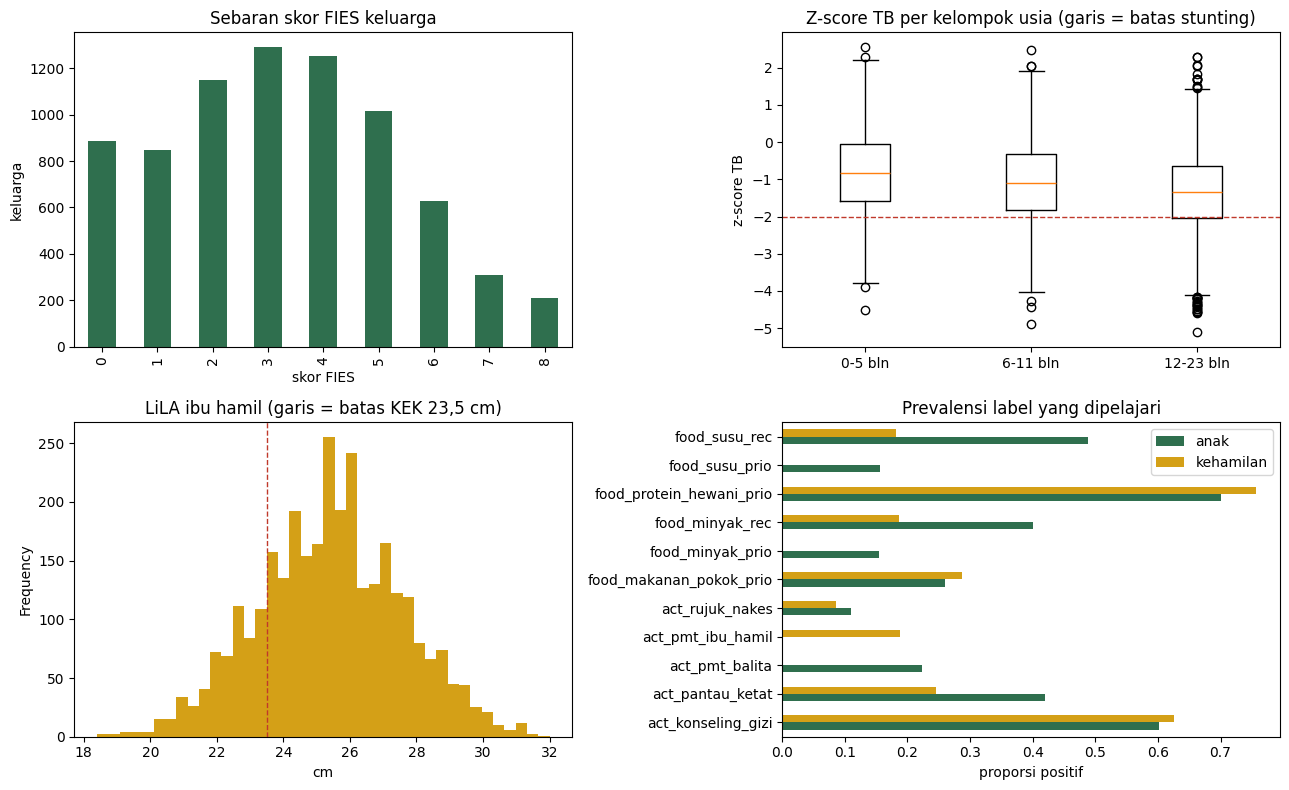

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

families["fies_score"].dropna().astype(int).value_counts().sort_index().plot.bar(ax=axes[0, 0], color="#2f6f4e")
axes[0, 0].set(title="Sebaran skor FIES keluarga", xlabel="skor FIES", ylabel="keluarga")

band_of = measured["age_months"].map(lambda a: fr.age_band(int(a)))
axes[0, 1].boxplot([measured.loc[band_of == b, "haz"] for b in fr.AGE_BANDS])
axes[0, 1].set_xticks([1, 2, 3], ["0-5 bln", "6-11 bln", "12-23 bln"])
axes[0, 1].axhline(-2, color="#c0392b", linestyle="--", linewidth=1)
axes[0, 1].set(title="Z-score TB per kelompok usia (garis = batas stunting)", ylabel="z-score TB")

checked["lila_cm"].plot.hist(bins=40, ax=axes[1, 0], color="#d4a017")
axes[1, 0].axvline(fr.MATERNAL_KEK_MUAC_CM, color="#c0392b", linestyle="--", linewidth=1)
axes[1, 0].set(title="LiLA ibu hamil (garis = batas KEK 23,5 cm)", xlabel="cm")

prevalence.plot.barh(ax=axes[1, 1], color=["#2f6f4e", "#d4a017"])
axes[1, 1].set(title="Prevalensi label yang dipelajari", xlabel="proporsi positif")
axes[1, 1].legend(["anak", "kehamilan"])

plt.tight_layout()
plt.show()

## 6. Fitur dan pembagian data

- Fitur dihitung dengan `fr.member_features()`, fungsi yang sama dengan runtime.
- Nilai kosong ditangani dengan **indikator ketersediaan**. Contohnya, LiLA kosong menghasilkan `muac_available = 0` dan `muac_deficit = 0`, bukan LiLA = 0 cm.
- Pembagian train/validasi/test dilakukan **per keluarga**. Anggota satu keluarga berbagi FIES dan petugas yang sama; kalau tersebar di train dan test, hasil evaluasi akan terlalu optimistis.

In [9]:
fies_lookup = families.set_index("family_id")["fies_score"].to_dict()

split_rng = np.random.default_rng(SEED + 1)
shuffled = families["family_id"].to_numpy()[split_rng.permutation(len(families))]
n_train = int(SPLIT_SHARES["train"] * len(shuffled))
n_val = int(SPLIT_SHARES["val"] * len(shuffled))
split_of = {fid: "train" for fid in shuffled[:n_train]}
split_of.update({fid: "val" for fid in shuffled[n_train:n_train + n_val]})
split_of.update({fid: "test" for fid in shuffled[n_train + n_val:]})
members["split"] = members["family_id"].map(split_of)
families["split"] = families["family_id"].map(split_of)

datasets = {}
for mt in fr.MEMBER_TYPES:
    rows = members[members.member_type == mt]
    member_dicts = records(rows.drop(columns=list(fr.ALL_HEADS) + ["split"]))
    X = pd.DataFrame(
        [fr.member_features(m, fies_lookup[m["family_id"]]) for m in member_dicts],
        index=rows.index,
        columns=fr.FEATURE_NAMES[mt],
    )
    datasets[mt] = {"X": X, "Y": rows[list(fr.ALL_HEADS)], "split": rows["split"], "groups": rows["family_id"], "members": member_dicts}

summary = pd.DataFrame(
    {mt: datasets[mt]["split"].value_counts() for mt in fr.MEMBER_TYPES}
).loc[["train", "val", "test"]]
summary.loc["jumlah fitur"] = [len(fr.FEATURE_NAMES[mt]) for mt in fr.MEMBER_TYPES]
display(summary.rename(columns={"child": "anak", "pregnancy": "kehamilan"}))
assert not set(fr.ALL_HEADS) & (set(fr.FEATURE_NAMES["child"]) | set(fr.FEATURE_NAMES["pregnancy"])), "Label bocor ke fitur"
display(datasets["child"]["X"].head(3).T.head(20))

,anak,kehamilan
split,,
train,5168,2447
val,1097,542
test,1103,551
jumlah fitur,50,12


,1,2,3
fies_available,1.00,1.0,1.00
fies_score,4.00,4.0,4.00
fies_at_least_moderate,1.00,1.0,1.00
fies_severe,0.00,0.0,0.00
age_months,19.00,13.0,13.00
age_0_5,0.00,0.0,0.00
age_6_11,0.00,0.0,0.00
age_12_23,1.00,1.0,1.00
is_male,1.00,1.0,1.00
has_measurement,1.00,0.0,1.00


## 7. Pelatihan

Untuk setiap jenis sasaran dan setiap keputusan yang dipelajari:

1. Fitur distandardisasi dengan `StandardScaler` yang di-fit pada data train.
2. Logistic regression dilatih dengan regularisasi `C` yang dipilih lewat 5-fold cross-validation **berkelompok per keluarga** (log-loss, agar probabilitas terkalibrasi).
3. Ambang keputusan dipilih pada data validasi dengan skor F-beta:
   - **F1** untuk keputusan biasa;
   - **F2** untuk keputusan keselamatan (rujuk dan pantau ulang), yaitu recall dihitung dua kali lebih penting karena melewatkan anak yang perlu dirujuk lebih berbahaya daripada rujukan berlebih.

   Ambang dicari di rentang 0,30-0,70. Kalau beberapa ambang memberi skor hampir sama (selisih < 0,01), dipilih yang paling dekat 0,5. Set validasi kecil dan berisik, jadi ambang ekstrem biasanya hanya mengikuti noise.

   Batas recall yang keras (misalnya >= 95%) sengaja tidak dipakai. Label petugas mengandung 2% inkonsistensi acak; mengejar recall pada label acak itu akan menurunkan ambang sampai anak normal pun ikut dirujuk. Kasus berat tetap dijamin oleh aturan keamanan.

Logistic regression dipilih karena (a) bobotnya bisa dibaca sehingga setiap rekomendasi punya alasan, (b) inferensinya cukup dengan Python standar di backend, dan (c) di bagian 8 terbukti tidak kalah dari model nonlinear.

In [10]:
C_GRID = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]
SAFETY_HEADS = ("act_rujuk_nakes", "act_pantau_ketat")  # recall diutamakan (F2)
THRESHOLD_GRID = np.round(np.arange(0.30, 0.701, 0.01), 2)  # dibatasi agar tidak mengikuti noise validasi


def choose_threshold(y: np.ndarray, p: np.ndarray, beta: float = 1.0, tolerance: float = 0.01) -> float:
    """Best F-beta on validation; among near-ties pick the threshold closest to 0.5 (more stable)."""
    scores = np.array([fbeta_score(y, p >= t, beta=beta, zero_division=0) for t in THRESHOLD_GRID])
    near_best = THRESHOLD_GRID[scores >= scores.max() - tolerance]
    return float(near_best[np.argmin(np.abs(near_best - 0.5))])


trained = {}
for mt in fr.MEMBER_TYPES:
    d = datasets[mt]
    is_train, is_val = d["split"].eq("train"), d["split"].eq("val")
    scaler = StandardScaler().fit(d["X"][is_train])
    Xs = pd.DataFrame(scaler.transform(d["X"]), index=d["X"].index, columns=d["X"].columns)
    heads = {}
    for head in fr.LEARNED_HEADS[mt]:
        y = d["Y"][head]
        search = GridSearchCV(
            LogisticRegression(max_iter=5000),
            {"C": C_GRID},
            scoring="neg_log_loss",
            cv=GroupKFold(n_splits=5),
            n_jobs=-1,
        )
        search.fit(Xs[is_train], y[is_train], groups=d["groups"][is_train])
        clf = search.best_estimator_
        beta = 2.0 if head in SAFETY_HEADS else 1.0
        threshold = choose_threshold(y[is_val].to_numpy(), clf.predict_proba(Xs[is_val])[:, 1], beta)
        heads[head] = {"clf": clf, "threshold": threshold, "C": search.best_params_["C"]}
        print(f"{mt:<9} {head:<26} C={heads[head]['C']:<5} ambang={threshold:.2f}")
    trained[mt] = {"scaler": scaler, "Xs": Xs, "heads": heads}

child     food_protein_hewani_prio   C=0.3   ambang=0.50
child     food_makanan_pokok_prio    C=0.1   ambang=0.50
child     food_susu_rec              C=1.0   ambang=0.50
child     food_susu_prio             C=0.3   ambang=0.50
child     food_minyak_rec            C=0.3   ambang=0.50
child     food_minyak_prio           C=0.3   ambang=0.50
child     act_rujuk_nakes            C=0.1   ambang=0.50
child     act_pantau_ketat           C=0.1   ambang=0.50
child     act_konseling_gizi         C=0.1   ambang=0.50
child     act_pmt_balita             C=0.3   ambang=0.50
pregnancy food_protein_hewani_prio   C=0.3   ambang=0.50
pregnancy food_makanan_pokok_prio    C=0.3   ambang=0.50
pregnancy food_susu_rec              C=0.3   ambang=0.50
pregnancy food_minyak_rec            C=0.1   ambang=0.50
pregnancy act_rujuk_nakes            C=0.3   ambang=0.50
pregnancy act_pantau_ketat           C=1.0   ambang=0.50
pregnancy act_konseling_gizi         C=0.3   ambang=0.50
pregnancy act_pmt_ibu_hamil    

In [11]:
# Paket model dalam format yang dibaca runtime (fr.load_model). Dibangun sekarang agar
# evaluasi di bagian berikutnya memakai jalur inferensi yang sama dengan aplikasi.
model_payload = {
    "format": fr.MODEL_FORMAT,
    "model_version": MODEL_VERSION,
    "trained_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "training_data": {
        "source": "synthetic",
        "seed": SEED,
        "n_families": int(len(families)),
        "n_members": int(len(members)),
        "label_noise": LABEL_NOISE,
        "n_raters": N_RATERS,
    },
    "member_types": {
        mt: {
            "features": list(fr.FEATURE_NAMES[mt]),
            "mean": trained[mt]["scaler"].mean_.tolist(),
            "scale": trained[mt]["scaler"].scale_.tolist(),
            "heads": {
                head: {
                    "coef": h["clf"].coef_[0].tolist(),
                    "intercept": float(h["clf"].intercept_[0]),
                    "threshold": h["threshold"],
                    "C": h["C"],
                }
                for head, h in trained[mt]["heads"].items()
            },
        }
        for mt in fr.MEMBER_TYPES
    },
}

# Uji kesetaraan: inferensi Python murni (runtime) harus sama dengan sklearn.
max_diff = 0.0
for mt in fr.MEMBER_TYPES:
    d, t = datasets[mt], trained[mt]
    is_test = d["split"].eq("test")
    test_members = [m for m, flag in zip(d["members"], is_test) if flag]
    runtime = pd.DataFrame([fr.predict_member(model_payload, m, fies_lookup[m["family_id"]]) for m in test_members])
    for head, h in t["heads"].items():
        sklearn_p = h["clf"].predict_proba(t["Xs"][is_test])[:, 1]
        max_diff = max(max_diff, float(np.abs(runtime[head].to_numpy() - sklearn_p).max()))
print(f"Selisih maksimum probabilitas runtime vs sklearn: {max_diff:.2e}")
assert max_diff < 1e-9

Selisih maksimum probabilitas runtime vs sklearn: 4.44e-16


## 8. Evaluasi per sasaran

Tiga sudut pandang pada data **test** (keluarga yang tidak pernah dilihat saat pelatihan):

1. **Terhadap label petugas** (berisik). Skor ini tidak bisa mencapai 100% karena inkonsistensi 2% dan variasi ambang antarpetugas memang acak. Pada keputusan yang jarang (misalnya rujuk) dampaknya terhadap recall dan F1 lebih besar.
2. **Terhadap pedoman** (tanpa variasi). Ini mengukur apakah model menangkap aturan yang benar.
3. **Pembanding:**
   - *baseline mayoritas*: selalu menebak kelas terbanyak; model harus jauh lebih baik.
   - *gradient boosting*: model nonlinear; kalau AUC-nya tidak jauh lebih tinggi, logistic regression sudah cukup.

In [12]:
def metrics_row(y, p, threshold) -> dict:
    pred = p >= threshold
    both = len(np.unique(y)) == 2
    return {
        "prevalensi": y.mean(),
        "AUC": roc_auc_score(y, p) if both else np.nan,
        "presisi": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "akurasi": accuracy_score(y, pred),
        "Brier": brier_score_loss(y, p),
    }


rows = []
for mt in fr.MEMBER_TYPES:
    d, t = datasets[mt], trained[mt]
    is_train, is_test = d["split"].eq("train"), d["split"].eq("test")
    test_members = [m for m, flag in zip(d["members"], is_test) if flag]
    guideline = pd.DataFrame(
        [label_member(m, fies_lookup[m["family_id"]], GUIDELINE) for m in test_members],
        index=d["X"].index[is_test],
    )
    for head, h in t["heads"].items():
        y = d["Y"][head][is_test].to_numpy()
        p = h["clf"].predict_proba(t["Xs"][is_test])[:, 1]
        row = {"sasaran": mt, "keputusan": head, **metrics_row(y, p, h["threshold"])}
        g = guideline[head].to_numpy()
        row["akurasi vs pedoman"] = accuracy_score(g, p >= h["threshold"])
        row["recall vs pedoman"] = recall_score(g, p >= h["threshold"], zero_division=0)
        row["F1 vs pedoman"] = f1_score(g, p >= h["threshold"], zero_division=0)
        row["akurasi baseline mayoritas"] = max(y.mean(), 1 - y.mean())
        gbm = HistGradientBoostingClassifier(random_state=SEED).fit(d["X"][is_train], d["Y"][head][is_train])
        row["AUC gradient boosting"] = roc_auc_score(y, gbm.predict_proba(d["X"][is_test])[:, 1])
        rows.append(row)

member_metrics = pd.DataFrame(rows)
display(
    member_metrics.style.format(
        {c: "{:.3f}" for c in member_metrics.columns if c not in ("sasaran", "keputusan")}
    ).background_gradient(subset=["F1", "F1 vs pedoman"], cmap="Greens", vmin=0.7, vmax=1.0)
)
print(f"Rata-rata F1 vs label petugas : {member_metrics['F1'].mean():.3f}")
print(f"Rata-rata F1 vs pedoman       : {member_metrics['F1 vs pedoman'].mean():.3f}")
print(f"Selisih AUC GBM - LR (maks)   : {(member_metrics['AUC gradient boosting'] - member_metrics['AUC']).max():+.3f}")

,sasaran,keputusan,prevalensi,AUC,presisi,recall,F1,akurasi,Brier,akurasi vs pedoman,recall vs pedoman,F1 vs pedoman,akurasi baseline mayoritas,AUC gradient boosting
0,child,food_protein_hewani_prio,0.701,0.952,0.951,0.973,0.962,0.946,0.051,1.000,1.000,1.000,0.701,0.956
1,child,food_makanan_pokok_prio,0.245,0.956,0.939,0.856,0.895,0.951,0.045,1.000,1.000,1.000,0.755,0.957
2,child,food_susu_rec,0.492,0.989,0.980,1.000,0.990,0.990,0.010,1.000,1.000,1.000,0.508,0.988
3,child,food_susu_prio,0.150,0.981,0.901,0.880,0.890,0.967,0.030,1.000,1.000,1.000,0.850,0.982
4,child,food_minyak_rec,0.391,0.989,0.981,0.951,0.966,0.974,0.025,1.000,1.000,1.000,0.609,0.989
5,child,food_minyak_prio,0.148,0.950,0.903,0.798,0.847,0.957,0.038,1.000,1.000,1.000,0.852,0.952
6,child,act_rujuk_nakes,0.089,0.926,0.950,0.776,0.854,0.976,0.022,1.000,1.000,1.000,0.911,0.929
7,child,act_pantau_ketat,0.398,0.957,0.921,0.904,0.913,0.931,0.061,1.000,1.000,1.000,0.602,0.968
8,child,act_konseling_gizi,0.593,0.958,0.943,0.956,0.949,0.939,0.056,1.000,1.000,1.000,0.593,0.963
9,child,act_pmt_balita,0.205,0.959,0.882,0.863,0.872,0.948,0.045,0.999,0.995,0.998,0.795,0.969


Rata-rata F1 vs label petugas : 0.916
Rata-rata F1 vs pedoman       : 1.000
Selisih AUC GBM - LR (maks)   : +0.013


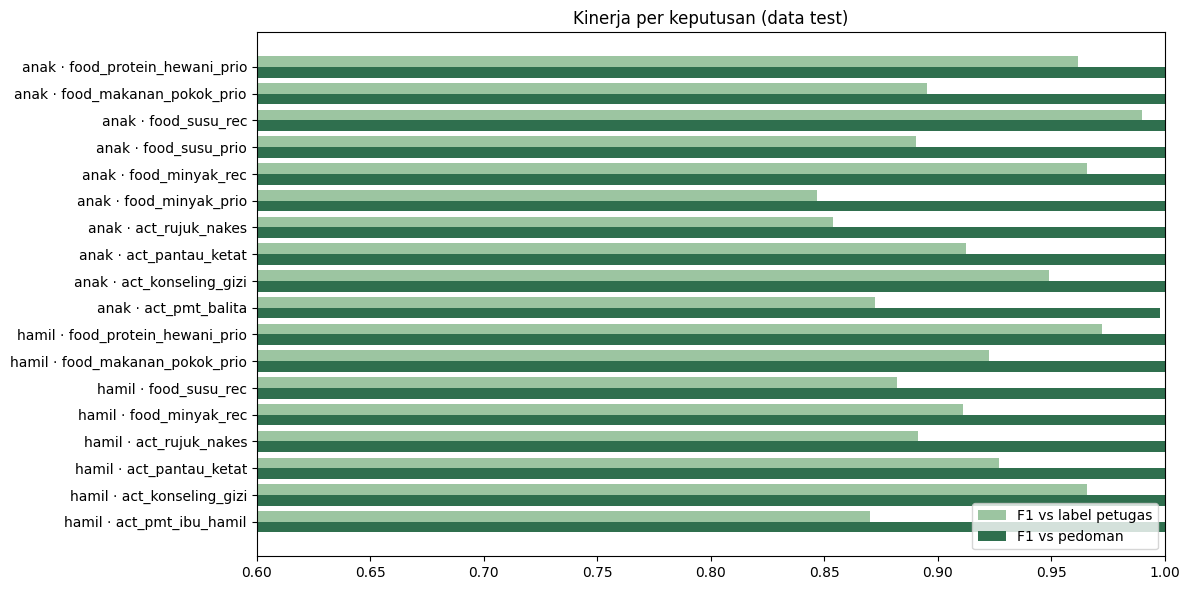

In [13]:
fig, ax = plt.subplots(figsize=(12, 6))
labels = member_metrics["sasaran"].map({"child": "anak", "pregnancy": "hamil"}) + " · " + member_metrics["keputusan"]
y_pos = np.arange(len(member_metrics))
ax.barh(y_pos - 0.2, member_metrics["F1"], height=0.4, label="F1 vs label petugas", color="#9cc5a1")
ax.barh(y_pos + 0.2, member_metrics["F1 vs pedoman"], height=0.4, label="F1 vs pedoman", color="#2f6f4e")
ax.set_yticks(y_pos, labels)
ax.set_xlim(0.6, 1.0)
ax.invert_yaxis()
ax.set_title("Kinerja per keputusan (data test)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

min_f1_guideline = member_metrics["F1 vs pedoman"].min()
assert min_f1_guideline >= 0.90, f"Ada keputusan dengan F1 vs pedoman {min_f1_guideline:.3f} < 0,90"
safety = member_metrics[member_metrics["keputusan"].isin(SAFETY_HEADS)]
assert (safety["recall vs pedoman"] >= 0.95).all(), "Recall keputusan keselamatan terhadap pedoman < 95%"

### Bobot yang dipelajari

Bobot positif menaikkan peluang keputusan. Bobot inilah yang dipakai runtime untuk menyusun alasan pada kartu, misalnya "Pendek dan tren menurun".

In [14]:
def top_weights(mt: str, head: str, n: int = 6) -> pd.Series:
    coef = pd.Series(trained[mt]["heads"][head]["clf"].coef_[0], index=fr.FEATURE_NAMES[mt])
    return coef.reindex(coef.abs().sort_values(ascending=False).index).head(n).round(2)


for mt, head in [("child", "food_protein_hewani_prio"), ("child", "act_rujuk_nakes"), ("child", "act_pmt_balita"), ("pregnancy", "food_protein_hewani_prio")]:
    print(f"\n{mt} / {head}")
    print(top_weights(mt, head).rename(index=lambda name: f"{name}  ({fr.FEATURE_LABELS.get(name, name)})").to_string())


child / food_protein_hewani_prio
age_6_11  (Usia 6-11 bulan (awal MP-ASI))                                            1.90
fies_at_least_moderate_x_age_12_23  (Keluarga rawan pangan pada usia 12-23 bulan)    1.22
age_0_5  (Usia 0-5 bulan (ASI eksklusif))                                           -1.07
fies_score  (Skor FIES keluarga)                                                     0.82
age_12_23  (Usia 12-23 bulan)                                                       -0.75
at_risk_x_age_6_11  (Masalah atau tren pertumbuhan menurun pada usia 6-11 bulan)    -0.67

child / act_rujuk_nakes
severely_stunted  (Sangat pendek (z-score TB < -3))                    1.34
severely_underweight  (Berat badan sangat kurang (z-score BB < -3))    0.98
stunted_and_declining  (Pendek dan tren menurun)                       0.77
muac_severe  (LiLA anak < 11,5 cm (gizi buruk))                        0.49
stunted  (Pendek (z-score TB < -2))                                    0.33
delta_haz  (Perubahan

## 9. Evaluasi tingkat keluarga (akumulasi)

Petugas faskes melihat rekomendasi **keluarga**, bukan rekomendasi per sasaran. Bagian ini menjalankan pipeline lengkap `fr.recommend_family()` untuk setiap keluarga test, lalu membandingkannya dengan hasil agregasi label pedoman:

- tingkat kebutuhan setiap kelompok pangan (tidak / dianjurkan / prioritas);
- himpunan tindakan;
- prioritas keluarga.

Bagian ini juga menghitung seberapa sering kebijakan atau aturan keamanan harus **mengoreksi** model. Kalau koreksi sering terjadi, berarti model belum belajar dengan baik.

In [15]:
member_dicts_by_family = {}
for mt in fr.MEMBER_TYPES:
    for m in datasets[mt]["members"]:
        member_dicts_by_family.setdefault(m["family_id"], []).append(m)

test_families = families[families["split"] == "test"]
family_rows, override_counts, n_member_results = [], {}, 0
for fam in records(test_families):
    fam_members = sorted(member_dicts_by_family.get(fam["family_id"], []), key=lambda m: m["member_id"])
    family_input = {"fies_score": fam["fies_score"], "fies_days_since": fam["fies_days_since"], "members": fam_members}
    predicted = fr.recommend_family(family_input, model_payload)
    expected = fr.aggregate_family(
        [fr.member_result(m, label_member(m, fam["fies_score"], GUIDELINE)) for m in fam_members],
        fam["fies_score"],
    )
    for m in predicted["members"]:
        n_member_results += 1
        for o in m["overrides"]:
            override_counts[(o["source"], o["head"])] = override_counts.get((o["source"], o["head"]), 0) + 1
    pred_levels = {g["key"]: g["level"] for g in predicted["food_groups"]}
    exp_levels = {g["key"]: g["level"] for g in expected["food_groups"]}
    family_rows.append({
        "n_sasaran": len(fam_members),
        **{f"pangan_{k}": pred_levels[k] == exp_levels[k] for k in fr.FOOD_GROUP_KEYS},
        "semua_pangan_sama": pred_levels == exp_levels,
        "tindakan_sama": {a["key"] for a in predicted["actions"]} == {a["key"] for a in expected["actions"]},
        "prioritas_sama": predicted["priority"] == expected["priority"],
    })

family_eval = pd.DataFrame(family_rows)
overall = family_eval.drop(columns="n_sasaran").mean().rename("semua keluarga")
by_size = family_eval.groupby("n_sasaran")[["semua_pangan_sama", "tindakan_sama", "prioritas_sama"]].mean()
display(overall.to_frame().style.format("{:.1%}"))
display(by_size.style.format("{:.1%}").set_caption("Kecocokan per jumlah sasaran dalam keluarga"))

override_table = pd.Series(override_counts, dtype=float).rename("jumlah")
override_rate = sum(override_counts.values()) / max(n_member_results, 1)
print(f"Koreksi oleh kebijakan/keamanan: {sum(override_counts.values())} dari {n_member_results} sasaran ({override_rate:.2%})")
if len(override_table):
    display(override_table.sort_values(ascending=False).to_frame())
assert overall["prioritas_sama"] >= 0.90 and overall["tindakan_sama"] >= 0.80

,semua keluarga
pangan_protein_hewani,100.0%
pangan_makanan_pokok,100.0%
pangan_sayuran,100.0%
pangan_buah,100.0%
pangan_susu,100.0%
pangan_minyak,100.0%
semua_pangan_sama,100.0%
tindakan_sama,99.9%
prioritas_sama,100.0%


,semua_pangan_sama,tindakan_sama,prioritas_sama
n_sasaran,,,
1,100.0%,100.0%,100.0%
2,100.0%,99.7%,100.0%
3,100.0%,100.0%,100.0%


Koreksi oleh kebijakan/keamanan: 0 dari 1654 sasaran (0.00%)


## 10. Uji skenario

Kasus yang ditulis tangan untuk memastikan rekomendasi masuk akal secara klinis dan program, termasuk akumulasi beberapa sasaran. Semua skenario harus **LULUS**; kalau ada yang gagal, sel ini berhenti dengan error.

In [16]:
WEEKLY_AID_PER_BENEFICIARY = {"severe": 100_000, "moderate": 75_000, "food_secure": 50_000}  # = family_aid_quota.py


def weekly_quota(fies_score, n_beneficiaries: int) -> int:
    cls = fies_classification(fies_score)
    return WEEKLY_AID_PER_BENEFICIARY.get(cls, 0) * n_beneficiaries


def child(name, age, haz=None, waz=None, muac=None, prev_haz=None, prev_waz=None, sex="female"):
    return {"member_type": "child", "name": name, "age_months": age, "sex": sex, "haz": haz, "waz": waz,
            "muac_cm": muac, "prev_haz": prev_haz, "prev_waz": prev_waz, "days_since_measurement": 10}


def pregnancy(name, weeks, lila=None, classification=None):
    return {"member_type": "pregnancy", "name": name, "gestational_weeks": weeks, "lila_cm": lila,
            "prenatal_classification": classification, "days_since_check": 10}


SCENARIOS = [
    {
        "nama": "Ibu hamil KEK trimester 3, FIES sedang",
        "keluarga": {"fies_score": 4, "members": [pregnancy("Ibu Sari", 32, 21.8, "kek_risk")]},
        "pangan": {"protein_hewani": 2, "makanan_pokok": 2, "susu": 1, "minyak": 1},
        "ada": ["pmt_ibu_hamil", "pantau_ketat", "konseling_gizi", "tinjau_akses_pangan"],
        "tidak": ["rujuk_nakes"],
        "prioritas": "medium",
    },
    {
        "nama": "Bayi 3 bulan normal, keluarga aman pangan",
        "keluarga": {"fies_score": 1, "members": [child("Bayi Ana", 3, -0.5, -0.3, None, -0.4, -0.2)]},
        "pangan": {"protein_hewani": 1, "susu": 0, "minyak": 0},
        "ada": [],
        "tidak": ["pmt_balita", "rujuk_nakes", "pantau_ketat", "konseling_gizi"],
        "prioritas": "low",
    },
    {
        "nama": "Anak 9 bulan stunting, FIES berat",
        "keluarga": {"fies_score": 7, "members": [child("Budi", 9, -2.6, -1.6, 13.0, -2.4, -1.5, "male")]},
        "pangan": {"protein_hewani": 2, "makanan_pokok": 2, "minyak": 1, "susu": 0},
        "ada": ["pantau_ketat", "konseling_gizi", "tinjau_akses_pangan"],
        "tidak": ["rujuk_nakes", "pmt_balita"],
        "prioritas": "high",
    },
    {
        "nama": "Anak 18 bulan masih normal tetapi tren turun",
        "keluarga": {"fies_score": 2, "members": [child("Citra", 18, -1.4, -1.0, 13.8, -0.9, -0.8)]},
        "pangan": {"protein_hewani": 2, "susu": 1},
        "ada": ["pantau_ketat", "konseling_gizi"],
        "tidak": ["rujuk_nakes", "pmt_balita"],
        "prioritas": "medium",
    },
    {
        "nama": "Anak 7 bulan LiLA 11,2 cm (gizi buruk)",
        "keluarga": {"fies_score": 3, "members": [child("Dodi", 7, -1.8, -2.7, 11.2, -1.7, -2.3, "male")]},
        "pangan": {"protein_hewani": 2, "makanan_pokok": 2, "minyak": 2, "susu": 0},
        "ada": ["rujuk_nakes", "pmt_balita", "pantau_ketat"],
        "tidak": [],
        "prioritas": "high",
    },
    {
        "nama": "Pemeriksaan kehamilan perlu ditinjau (DJJ menyimpang)",
        "keluarga": {"fies_score": 1, "members": [pregnancy("Ibu Rina", 30, 25.0, "needs_review")]},
        "pangan": {"protein_hewani": 2, "susu": 0},
        "ada": ["rujuk_nakes", "pantau_ketat"],
        "tidak": ["pmt_ibu_hamil"],
        "prioritas": "high",
    },
    {
        "nama": "Akumulasi: ibu hamil normal + anak 14 bulan pendek, FIES sedang",
        "keluarga": {"fies_score": 5, "members": [pregnancy("Ibu Wati", 20, 24.5, "normal"), child("Eko", 14, -2.2, -1.9, 13.2, -2.1, -1.8, "male")]},
        "pangan": {"protein_hewani": 2, "susu": 2, "minyak": 0},
        "ada": ["pantau_ketat", "konseling_gizi", "tinjau_akses_pangan"],
        "tidak": ["rujuk_nakes", "pmt_ibu_hamil"],
        "prioritas": "medium",
        "skor_pangan": {"protein_hewani": 4, "sayuran": 2},
    },
    {
        "nama": "Anak 30 bulan di luar sasaran + bayi 2 bulan",
        "keluarga": {"fies_score": 0, "members": [child("Fajar", 30, -2.5, -2.0), child("Gita", 2, 0.1, 0.2)]},
        "pangan": {"susu": 0, "minyak": 0},
        "ada": [],
        "tidak": ["rujuk_nakes"],
        "prioritas": "low",
        "dikecualikan": 1,
    },
    {
        "nama": "FIES belum diisi, anak 10 bulan belum diukur",
        "keluarga": {"fies_score": None, "members": [child("Hana", 10)]},
        "pangan": {"protein_hewani": 2, "minyak": 1, "susu": 0},
        "ada": [],
        "tidak": ["tinjau_akses_pangan", "rujuk_nakes", "pantau_ketat"],
        "prioritas": "low",
        "cek_data": ["fies_missing", "measurement_missing"],
    },
]


def run_scenario(s: dict) -> tuple[bool, list[str], dict]:
    rec = fr.recommend_family(s["keluarga"], model_payload)
    levels = {g["key"]: g["level"] for g in rec["food_groups"]}
    scores = {g["key"]: g["score"] for g in rec["food_groups"]}
    actions = {a["key"] for a in rec["actions"]}
    problems = []
    problems += [f"pangan {k}={levels[k]} (harus {v})" for k, v in s["pangan"].items() if levels[k] != v]
    problems += [f"skor {k}={scores[k]} (harus {v})" for k, v in s.get("skor_pangan", {}).items() if scores[k] != v]
    problems += [f"tindakan {a} tidak muncul" for a in s["ada"] if a not in actions]
    problems += [f"tindakan {a} seharusnya tidak muncul" for a in s["tidak"] if a in actions]
    if rec["priority"] != s["prioritas"]:
        problems.append(f"prioritas {rec['priority']} (harus {s['prioritas']})")
    if "dikecualikan" in s and len(rec["excluded_members"]) != s["dikecualikan"]:
        problems.append(f"sasaran dikecualikan {len(rec['excluded_members'])}")
    checks = {c["key"] for c in rec["data_checks"]}
    problems += [f"cek data {c} tidak muncul" for c in s.get("cek_data", []) if c not in checks]
    return not problems, problems, rec


scenario_rows = []
for s in SCENARIOS:
    ok, problems, rec = run_scenario(s)
    scenario_rows.append({
        "skenario": s["nama"],
        "hasil": "LULUS" if ok else "GAGAL",
        "prioritas": rec["priority"],
        "tindakan": ", ".join(a["key"] for a in rec["actions"]),
        "pangan prioritas": ", ".join(g["key"] for g in rec["food_groups"] if g["level"] == 2),
        "catatan": "; ".join(problems),
    })
scenario_table = pd.DataFrame(scenario_rows)
display(scenario_table)
assert (scenario_table["hasil"] == "LULUS").all(), "Ada skenario yang gagal"

,skenario,hasil,prioritas,tindakan,pangan prioritas,catatan
0,"Ibu hamil KEK trimester 3, FIES sedang",LULUS,medium,"pantau_ketat, pmt_ibu_hamil, konseling_gizi, t...","protein_hewani, makanan_pokok",
1,"Bayi 3 bulan normal, keluarga aman pangan",LULUS,low,,,
2,"Anak 9 bulan stunting, FIES berat",LULUS,high,"pantau_ketat, konseling_gizi, tinjau_akses_pangan","protein_hewani, makanan_pokok",
3,Anak 18 bulan masih normal tetapi tren turun,LULUS,medium,"pantau_ketat, konseling_gizi",protein_hewani,
4,"Anak 7 bulan LiLA 11,2 cm (gizi buruk)",LULUS,high,"rujuk_nakes, pantau_ketat, pmt_balita, konseli...","protein_hewani, makanan_pokok, minyak",
5,Pemeriksaan kehamilan perlu ditinjau (DJJ meny...,LULUS,high,"rujuk_nakes, pantau_ketat",protein_hewani,
6,Akumulasi: ibu hamil normal + anak 14 bulan pe...,LULUS,medium,"pantau_ketat, konseling_gizi, tinjau_akses_pangan","protein_hewani, susu",
7,Anak 30 bulan di luar sasaran + bayi 2 bulan,LULUS,low,,,
8,"FIES belum diisi, anak 10 bulan belum diukur",LULUS,low,,protein_hewani,


## 11. Contoh keluaran untuk kartu faskes

Contoh berikut adalah keluarga dengan ibu hamil KEK dan anak 9 bulan pendek. Anggarannya adalah kuota mingguan menurut aturan `family_aid_quota.py`, dan katalognya adalah produk contoh dari `seed_database.py`.

Keranjang disusun mulai dari produk termurah di setiap kelompok, satu unit per produk per putaran agar bervariasi. Sisa anggaran (termasuk anggaran kelompok yang belum punya produk di katalog, misalnya minyak) dipakai untuk kelompok yang paling dibutuhkan.

In [17]:
DEMO_CATALOG = [
    {"id": "p1", "name": "Beras Premium 5kg", "category": "Beras", "price": 75000, "stock": 120},
    {"id": "p2", "name": "Telur Ayam 1kg", "category": "Protein", "price": 32000, "stock": 90},
    {"id": "p3", "name": "Bayam Segar", "category": "Sayuran", "price": 10000, "stock": 80},
    {"id": "p4", "name": "Pisang Ambon", "category": "Buah", "price": 22000, "stock": 60},
    {"id": "p5", "name": "Susu UHT 1L", "category": "Susu", "price": 19000, "stock": 70},
    {"id": "p6", "name": "Ikan Kembung 1kg", "category": "Protein", "price": 45000, "stock": 55},
    {"id": "p7", "name": "Wortel Segar", "category": "Sayuran", "price": 12000, "stock": 65},
    {"id": "p8", "name": "Jeruk Manis", "category": "Buah", "price": 28000, "stock": 45},
    {"id": "p9", "name": "Ayam Potong 1kg", "category": "Protein", "price": 42000, "stock": 35},
    {"id": "p10", "name": "Yogurt Plain", "category": "Susu", "price": 16000, "stock": 25},
    {"id": "p11", "name": "Gula Pasir 1kg", "category": "Gula", "price": 18000, "stock": 50},
]

demo_family = {
    "fies_score": 6,
    "fies_days_since": 12,
    "members": [pregnancy("Ibu Lestari", 26, 22.4, "kek_risk"), child("Raka", 9, -2.3, -1.7, 12.9, -2.1, -1.5, "male")],
}
budget = weekly_quota(demo_family["fies_score"], len(demo_family["members"]))
demo = fr.recommend_family(demo_family, model_payload, weekly_budget=budget, products=DEMO_CATALOG)


def rupiah(value) -> str:
    return "Rp" + f"{value:,.0f}".replace(",", ".")


def print_card(rec: dict) -> None:
    print(f"PRIORITAS KELUARGA: {rec['priority'].upper()}   (model {rec['model_version']})")
    print("\nREKOMENDASI TINDAKAN")
    for a in rec["actions"]:
        print(f"  • {a['label']} — {', '.join(a['members'])}  [{', '.join(a['sources'])}]")
    if rec["data_checks"]:
        print("\nLENGKAPI DATA")
        for c in rec["data_checks"]:
            print(f"  • {c['label']} — {c['member']}")
    print(f"\nREKOMENDASI PANGAN (kuota minggu ini {rupiah(rec['weekly_budget'] or 0)})")
    for g in rec["food_groups"]:
        if not g["level"]:
            continue
        print(f"  • {g['label']:<20} {g['level_label']:<11} {g['share']:>5.0%}  {rupiah(g['budget'] or 0):>10}"
              f"  kategori: {', '.join(g['catalog_categories'])}")
        for m in g["members"]:
            reason = f" ({'; '.join(m['reasons'])})" if m["reasons"] else ""
            print(f"      - {m['member']}: {m['level']}{reason}")
    if "basket" in rec:
        b = rec["basket"]
        print(f"\nCONTOH KERANJANG ({rupiah(b['total'])}, sisa {rupiah(b['unspent'])})")
        for item in b["items"]:
            print(f"  • {item['quantity']} x {item['name']:<20} {rupiah(item['subtotal']):>10}  [{item['group']}]")
        if b["groups_without_products"]:
            print(f"  Belum ada produk di katalog untuk: {', '.join(b['groups_without_products'])}")
    print("\nTIDAK DIREKOMENDASIKAN: " + "; ".join(f"{n['category']} ({n['reason']})" for n in rec["not_recommended"]))
    print("\nSASARAN")
    for m in rec["members"]:
        print(f"  • {m['label']}: {m['summary']}")
    for e in rec["excluded_members"]:
        print(f"  • {e['member']}: dikecualikan — {e['reason']}")


print_card(demo)
assert demo["basket"]["total"] <= budget
assert sum(g["budget"] or 0 for g in demo["food_groups"]) == budget
assert not any(item["category"] == "Gula" for item in demo["basket"]["items"])

PRIORITAS KELUARGA: HIGH   (model family-reco-v1-synthetic)

REKOMENDASI TINDAKAN
  • Pantau ulang dalam 2 minggu — Ibu Lestari, Raka  [model]
  • Makanan tambahan (PMT) ibu hamil KEK — Ibu Lestari  [model]
  • Berikan konseling gizi — Ibu Lestari, Raka  [model]
  • Tinjau akses pangan keluarga — Keluarga  [aturan_fies]

REKOMENDASI PANGAN (kuota minggu ini Rp200.000)
  • Protein hewani       prioritas     48%    Rp96.000  kategori: protein
      - Ibu Lestari: prioritas (Risiko KEK (LiLA ibu < 23,5 cm); Keluarga rawan pangan (FIES >= 3))
      - Raka: prioritas (Usia 6-11 bulan (awal MP-ASI))
  • Makanan pokok        prioritas     24%    Rp48.000  kategori: beras, pokok
      - Ibu Lestari: prioritas (Risiko KEK (LiLA ibu < 23,5 cm); Keluarga rawan pangan berat (FIES >= 6))
      - Raka: prioritas (Keluarga rawan pangan berat (FIES >= 6))
  • Sayuran              dianjurkan     8%    Rp16.000  kategori: sayuran
      - Ibu Lestari: dianjurkan (Kebutuhan gizi seimbang harian (Isi Pirin

In [18]:
# Bentuk JSON yang nantinya dikirim API ke frontend (dipotong agar ringkas).
preview = {k: demo[k] for k in ("priority", "model_version", "weekly_budget")}
preview["actions"] = demo["actions"][:2]
preview["food_groups"] = demo["food_groups"][:2]
print(json.dumps(preview, indent=2, ensure_ascii=False))

{
  "priority": "high",
  "model_version": "family-reco-v1-synthetic",
  "weekly_budget": 200000,
  "actions": [
    {
      "key": "pantau_ketat",
      "label": "Pantau ulang dalam 2 minggu",
      "description": "Ukur ulang pertumbuhan atau periksa ulang kehamilan lebih cepat dari jadwal rutin.",
      "members": [
        "Ibu Lestari",
        "Raka"
      ],
      "sources": [
        "model"
      ]
    },
    {
      "key": "pmt_ibu_hamil",
      "label": "Makanan tambahan (PMT) ibu hamil KEK",
      "description": "Makanan tambahan tinggi energi dan protein untuk ibu hamil dengan LiLA di bawah 23,5 cm.",
      "members": [
        "Ibu Lestari"
      ],
      "sources": [
        "model"
      ]
    }
  ],
  "food_groups": [
    {
      "key": "protein_hewani",
      "label": "Protein hewani",
      "examples": "telur, ikan, ayam, daging",
      "catalog_categories": [
        "protein"
      ],
      "level": 2,
      "level_label": "prioritas",
      "score": 4,
      "membe

## 12. Ekspor artefak

1. Model disimpan ke folder artefak pelatihan **dan** disalin ke `app/services/family_recommender_model.json` untuk runtime.
2. Salinan runtime dimuat ulang dengan `fr.load_model()`. Fungsi ini menolak model yang daftar fitur atau keputusannya tidak sama dengan modul, sehingga perbedaan antara training dan runtime langsung ketahuan.
3. Laporan evaluasi disimpan ke `family_recommender_metrics.json` untuk dokumentasi atau laporan.

In [19]:
model_json = json.dumps(model_payload, indent=2)
(ARTIFACT_DIR / "family_recommender_model.json").write_text(model_json, encoding="utf-8")
RUNTIME_MODEL_FILE.write_text(model_json, encoding="utf-8")

reloaded = fr.load_model(RUNTIME_MODEL_FILE)
check = fr.recommend_family(demo_family, reloaded, weekly_budget=budget, products=DEMO_CATALOG)
assert check["food_groups"] == demo["food_groups"] and check["actions"] == demo["actions"]

metrics_report = {
    "model_version": MODEL_VERSION,
    "trained_at": model_payload["trained_at"],
    "data": {
        "families": int(len(families)),
        "members": {mt: int((members.member_type == mt).sum()) for mt in fr.MEMBER_TYPES},
        "split": {name: int((families.split == name).sum()) for name in ("train", "val", "test")},
        "quality": quality.to_dict("records"),
    },
    "member_level_test": member_metrics.round(4).to_dict("records"),
    "family_level_test": {
        "overall": overall.round(4).to_dict(),
        "by_number_of_targets": by_size.round(4).reset_index().to_dict("records"),
        "override_rate": round(override_rate, 4),
    },
    "scenarios": scenario_table[["skenario", "hasil"]].to_dict("records"),
}
(ARTIFACT_DIR / "family_recommender_metrics.json").write_text(
    json.dumps(metrics_report, indent=2, ensure_ascii=False, default=str), encoding="utf-8"
)
for path in (ARTIFACT_DIR / "family_recommender_model.json", ARTIFACT_DIR / "family_recommender_metrics.json", RUNTIME_MODEL_FILE):
    print(f"{path.relative_to(PROJECT_ROOT)}  ({path.stat().st_size / 1024:.1f} KB)")

apps\backend\ml\family_recommender\artifacts\family_recommender_model.json  (28.9 KB)
apps\backend\ml\family_recommender\artifacts\family_recommender_metrics.json  (12.3 KB)
apps\backend\app\services\family_recommender_model.json  (28.9 KB)


## 13. Keterbatasan dan langkah berikutnya

**Keterbatasan**

- Label berasal dari pedoman yang dikodekan, sehingga model tidak bisa lebih pintar dari pedoman itu. Angka F1 menunjukkan seberapa setia model mengikuti pedoman, **bukan** dampak klinis di lapangan. Tuliskan hal ini secara eksplisit di laporan.
- Aturan pangan dan bobot biaya adalah rancangan awal dan perlu disahkan ahli gizi (keputusan terbuka #4 `idea.md`).
- Z-score aplikasi memakai tabel median/SD bulanan; untuk bayi 0-6 bulan hasilnya bisa bergeser cukup jauh. Perbaikan tabel WHO akan langsung meningkatkan kualitas masukan model.
- Tidak ada data hemoglobin (anemia) atau berat-menurut-tinggi; keduanya relevan bila kelak dicatat.

**Integrasi ke aplikasi**

1. Endpoint faskes `GET /facilities/families/{id}/recommendation` (`app/services/facility_recommendation.py`) mengambil FIES terakhir, anak beserta 2 pengukuran terakhir, dan kehamilan beserta pemeriksaan terakhir. Endpoint lalu memanggil `family_recommender.recommend_family()` dengan `weekly_budget` = sisa kuota mingguan keluarga.
2. Halaman detail keluarga (`FamilyDetail.tsx`) menampilkan kartu "Rekomendasi Tindakan" (`actions`, `data_checks`) dan "Rekomendasi Pangan" (`food_groups`).
3. Langkah berikutnya: memakai `basket` sebagai keranjang awal di katalog (perlu memperhitungkan aturan satu vendor per pesanan), dan menyimpan keputusan akhir petugas di `FamilyAidPlan.basis_snapshot`. Data itu kelak diekspor ke CSV dengan kolom yang sama untuk melatih ulang model dengan data nyata (set `REGENERATE_DATA = False`).